# 01 · Data quality and cleaning

**Roadmap step 1.** This notebook documents what was checked in the raw Sample
Superstore file, what was changed, and which assumptions the cleaned data relies on.

The cleaning itself lives in `src/cleaning.py` and the database build in
`src/build_database.py`; this notebook only reads their outputs, so every number
here is reproducible with:

```
python -m src.build_database
python -m pytest
```

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.build_database import DB_PATH, build_database
from src.cleaning import RAW_PATH, load_raw

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# The DuckDB file is not in git; build it if it is missing.
if not DB_PATH.exists():
    build_database()

con = duckdb.connect(str(DB_PATH), read_only=True)
pd.set_option("display.max_colwidth", 80)

In [2]:
# Shared chart style (light mode, reference palette from the dataviz guide).
SURFACE, TEXT, TEXT_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": TEXT,
})


def add_titles(fig, title, subtitle):
    # Left-aligned figure title and subtitle above the plot area.
    fig.text(0.015, 0.965, title, fontsize=12, fontweight="bold", color=TEXT, va="top")
    fig.text(0.015, 0.895, subtitle, fontsize=9, color=TEXT_2, va="top")
    fig.tight_layout(rect=(0, 0, 1, 0.86))

## 1. Data quality log

Every check run by the pipeline, with the number of rows it touched and the
action taken. Nothing in `data/raw/` is modified.

In [3]:
con.sql("SELECT * FROM data_quality_log").df()

,check,column,rows_affected,action
0,raw_row_count,all,9994,loaded raw file
1,missing_values,all,0,none needed
2,postal_code_leading_zero,postal_code,449,read as text and left-padded to 5 digits
3,encoding_cp1252_characters,product_name,43,none needed; decoded correctly by reading as cp1252
4,text_non_breaking_space,product_name,225,replaced non-breaking spaces with normal spaces
5,text_edge_whitespace,product_name,16,trimmed leading/trailing whitespace
6,text_total_changed,product_name,241,rows changed by any text fix (a row can match several)
7,near_duplicate_rows,all except row_id,1,"dropped row_id(s) [3407], kept first occurrence"
8,product_id_multiple_names,product_name,32,no change in order lines; dim_product uses most frequent name
9,constant_column,country,9993,dropped (single value 'United States')


**Reading the log:**

- **No missing values** in any of the 21 columns.
- **449 postal codes** lost their leading zero when read as numbers (New England
  states such as Massachusetts and Connecticut). They are now 5-character text.
- **Text:** 225 product names contained non-breaking spaces and 16 had
  leading/trailing spaces (no overlap), so 241 rows were changed.
- **One near-duplicate row** (row_id 3407) matched row 3406 in every column except
  `row_id` and was dropped.
- `country` has a single value (*United States*) and was dropped from the tables.

## 2. Reconciliation: raw file → cleaned data → star schema

The cleaned data must lose nothing except the one dropped row, and the star
schema must reproduce `orders_clean` exactly. The same checks run as
`tests/test_database.py`.

In [4]:
raw = load_raw(RAW_PATH)
dropped = con.sql("SELECT row_id FROM dropped_rows").df()["row_id"].tolist()


def totals(frame):
    return {
        "rows": len(frame),
        "sales": round(frame["sales"].sum(), 2),
        "profit": round(frame["profit"].sum(), 2),
        "quantity": int(frame["quantity"].sum()),
    }


raw_lower = raw.rename(columns=str.lower)
star = con.sql("""
    SELECT f.* FROM fact_order_lines f
    JOIN dim_customer c USING (customer_id)
    JOIN dim_product  p USING (product_id)
    JOIN dim_location l USING (location_id)
    JOIN dim_date     d ON f.order_date = d.date
""").df()

pd.DataFrame({
    "raw file": totals(raw_lower),
    "raw minus dropped rows": totals(raw_lower[~raw["Row ID"].isin(dropped)]),
    "orders_clean": totals(con.sql("SELECT * FROM orders_clean").df()),
    "fact joined to all dims": totals(star),
}).T

,rows,sales,profit,quantity
raw file,9994.0,2297200.86,286397.02,37873.0
raw minus dropped rows,9993.0,2296919.49,286409.08,37871.0
orders_clean,9993.0,2296919.49,286409.08,37871.0
fact joined to all dims,9993.0,2296919.49,286409.08,37871.0


The last three rows are identical: cleaning removed only row 3407 ($281.37 of
sales), and joining the fact table to every dimension neither drops nor
duplicates a single row.

## 3. Encoding: the file is Windows-1252, not latin-1

The dataset is usually described as latin-1. Reading it that way turns 43 product
names' smart quotes (bytes `0x93`/`0x94`) into invisible control characters.
Reading it as `cp1252` decodes them correctly, so no repair is needed.

In [5]:
names = load_raw(RAW_PATH)["Product Name"]
with_smart_quotes = names[names.str.contains("[\u201c\u201d]")]
print(f"{len(with_smart_quotes)} rows with smart quotes, e.g.:")
with_smart_quotes.drop_duplicates().head(3).to_frame()

43 rows with smart quotes, e.g.:


,Product Name
171,"Adams Phone Message Book, Professional, 400 Message Capacity, 5 3/6” x 11”"
276,"Post-it “Important Message” Note Pad, Neon Colors, 50 Sheets/Pad"
328,Hon 2090 “Pillow Soft” Series Mid Back Swivel/Tilt Chairs


## 4. Product IDs with more than one name

32 `product_id`s appear with two different names. `dim_product` needs one row per
id, so it uses the **most frequent name**; for 6 ids both names are equally
frequent and the tie is broken alphabetically. `orders_clean` keeps the original
name on every line.

In [6]:
variants = con.sql("SELECT * FROM product_name_variants").df()
print(f"{variants.product_id.nunique()} product_ids, "
      f"{variants.loc[variants.is_tie, 'product_id'].nunique()} with a tie")
variants.head(8)

32 product_ids, 6 with a tie


,product_id,product_name,line_count,is_chosen,is_tie
0,FUR-BO-10002213,DMI Eclipse Executive Suite Bookcases,6,True,False
1,FUR-BO-10002213,"Sauder Forest Hills Library, Woodland Oak Finish",4,False,False
2,FUR-CH-10001146,"Global Value Mid-Back Manager's Chair, Gray",10,True,False
3,FUR-CH-10001146,"Global Task Chair, Black",5,False,False
4,FUR-FU-10001473,DAX Wood Document Frame,9,True,False
5,FUR-FU-10001473,"Eldon Executive Woodline II Desk Accessories, Mahogany",5,False,False
6,FUR-FU-10004017,"Tenex Contemporary Contur Chairmats for Low and Medium Pile Carpet, Computer...",4,True,False
7,FUR-FU-10004017,"Executive Impressions 13"" Chairman Wall Clock",3,False,False


Some pairs are clearly **different products** sharing an id, not spelling
variants (e.g. a bookcase and a library shelf, or desk accessories and a wall
clock). The pricing check in section 6 confirms it. **Consequence:** product-level
results for these 32 ids should be read with care. Category and sub-category are
consistent for every id, so analysis at those levels is unaffected.

## 5. Locations: postal code is not a unique key

Postal code 92024 is used for both San Diego and Encinitas, so `dim_location` is
keyed on `location_id = postal_code|city|state` (632 locations).

In [7]:
con.sql("SELECT * FROM dim_location WHERE postal_code = '92024'").df()

,location_id,postal_code,city,state,region
0,92024|Encinitas|California,92024,Encinitas,California,West
1,92024|San Diego|California,92024,San Diego,California,West


## 6. Assumption: `sales` is recorded after discount

> **This is an assumption, not a fact stated by the data.** The dataset has no
> list-price column. `gross_sales = sales / (1 − discount)`, `discount_amount` and
> `unit_price` are all derived from it.

The data can still be tested against the assumption: if it holds, a product's
pre-discount unit price `sales / quantity / (1 − discount)` should be the same
whatever discount it was sold at.

In [8]:
price_check = con.sql("""
    WITH per_product AS (
        SELECT
            product_id,
            product_id IN (SELECT product_id FROM product_name_variants) AS multi_name,
            COUNT(DISTINCT discount) AS discount_levels,
            MAX(unit_price) / MIN(unit_price) - 1 AS price_spread
        FROM orders_clean
        GROUP BY product_id
    )
    SELECT
        multi_name,
        COUNT(*) FILTER (WHERE discount_levels > 1) AS sold_at_several_discounts,
        COUNT(*) FILTER (WHERE discount_levels > 1 AND price_spread <= 0.001)
            AS constant_gross_price
    FROM per_product
    GROUP BY multi_name
    ORDER BY multi_name
""").df()
price_check

,multi_name,sold_at_several_discounts,constant_gross_price
0,False,1530,1530
1,True,32,0


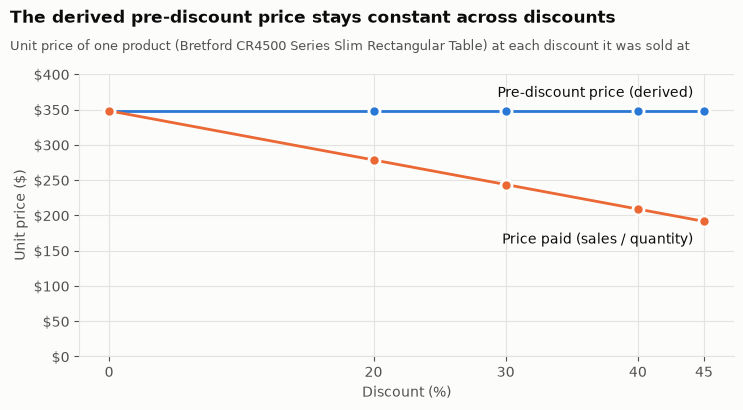

In [9]:
example_id = "FUR-TA-10000577"
example = con.sql(f"""
    SELECT discount,
           ANY_VALUE(sales / quantity) AS net_unit_price,
           ANY_VALUE(unit_price)       AS gross_unit_price
    FROM orders_clean
    WHERE product_id = '{example_id}'
    GROUP BY discount ORDER BY discount
""").df()
example_name = con.sql(
    f"SELECT product_name FROM dim_product WHERE product_id = '{example_id}'"
).fetchone()[0]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
x = example["discount"] * 100
ax.plot(x, example["gross_unit_price"], color=BLUE, lw=2, marker="o", ms=8,
        markeredgecolor=SURFACE, markeredgewidth=2)
ax.plot(x, example["net_unit_price"], color=ORANGE, lw=2, marker="o", ms=8,
        markeredgecolor=SURFACE, markeredgewidth=2)
last = example.iloc[-1]
ax.annotate("Pre-discount price (derived)", (x.iloc[-1], last.gross_unit_price),
            xytext=(-8, 10), textcoords="offset points", ha="right", color=TEXT)
ax.annotate("Price paid (sales / quantity)", (x.iloc[-1], last.net_unit_price),
            xytext=(-8, -16), textcoords="offset points", ha="right", color=TEXT)
ax.set_xlabel("Discount (%)")
ax.set_ylabel("Unit price ($)")
ax.set_ylim(0, example["gross_unit_price"].max() * 1.15)
ax.set_xticks(x)
ax.yaxis.set_major_formatter("${x:,.0f}")
add_titles(fig, "The derived pre-discount price stays constant across discounts",
           f"Unit price of one product ({example_name}) at each discount it was sold at")
fig.savefig(FIG_DIR / "01_gross_price_assumption.png", dpi=150)

**Result:** all 1,530 single-name products that were sold at more than one
discount level have a constant derived pre-discount price (within 0.1%). That is
exactly what the after-discount assumption predicts, so it is well supported,
but it remains an assumption. None of the 32 multi-name products pass, which is
further evidence that those ids mix different items.

## 7. Outliers: kept, flagged, and never used as ML features

`is_outlier_sales` and `is_outlier_profit` mark values outside 1.5 × IQR. The
extreme rows are real high-ticket lines (copiers, 3D printers, binding machines),
so they are **kept**.

> **Data-leakage warning:** the flags are for analysis only. They are computed
> from the full dataset's quartiles and from `sales`/`profit` themselves; profit is
> the target of the step 4 loss-risk model. Using them as features would leak the
> target (and test-set information) into the model. `fact_order_lines` excludes
> them for this reason.

In [10]:
outlier_share = con.sql("""
    SELECT
        AVG(is_outlier_profit::INT) AS "Order lines",
        SUM(sales) FILTER (WHERE is_outlier_profit) / SUM(sales) AS "Sales",
        SUM(profit) FILTER (WHERE is_outlier_profit AND profit > 0)
            / SUM(profit) FILTER (WHERE profit > 0) AS "Profit from gaining lines",
        SUM(profit) FILTER (WHERE is_outlier_profit AND profit < 0)
            / SUM(profit) FILTER (WHERE profit < 0) AS "Losses from losing lines"
    FROM orders_clean
""").df().T.rename(columns={0: "share"})
outlier_share.style.format("{:.1%}")

,share
Order lines,18.8%
Sales,67.9%
Profit from gaining lines,75.2%
Losses from losing lines,89.9%


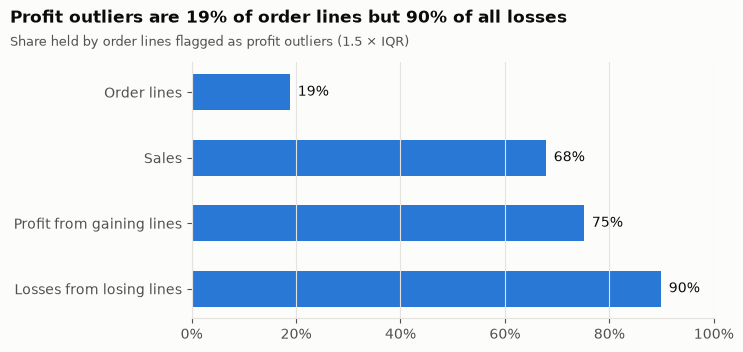

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
labels = outlier_share.index[::-1]
values = outlier_share["share"].values[::-1] * 100
bars = ax.barh(labels, values, color=BLUE, height=0.55)
for bar, value in zip(bars, values):
    ax.text(value + 1.5, bar.get_y() + bar.get_height() / 2, f"{value:.0f}%",
            va="center", color=TEXT)
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter("{x:.0f}%")
ax.grid(axis="y", visible=False)
add_titles(fig, "Profit outliers are 19% of order lines but 90% of all losses",
           "Share held by order lines flagged as profit outliers (1.5 × IQR)")
fig.savefig(FIG_DIR / "01_outlier_share.png", dpi=150)

In [12]:
large_losses = con.sql("""
    SELECT sub_category, COUNT(*) AS large_loss_lines, ROUND(SUM(profit)) AS loss
    FROM orders_clean
    WHERE is_outlier_profit AND profit < 0
    GROUP BY sub_category ORDER BY loss
""").df()
top3_share = large_losses["loss"].head(3).sum() / large_losses["loss"].sum()
print(f"Top 3 sub-categories hold {top3_share:.0%} of large-loss money "
      f"across {len(large_losses)} sub-categories")
large_losses.head(5)

Top 3 sub-categories hold 67% of large-loss money across 11 sub-categories


,sub_category,large_loss_lines,loss
0,Binders,96,-33415.0
1,Tables,147,-31319.0
2,Machines,34,-29952.0
3,Bookcases,59,-11159.0
4,Appliances,42,-8227.0


## Business insight

**The data is reliable enough to answer the core question.** No values are
missing, and the cleaned tables reconcile with the raw file to the cent. The
fixes were all small and are logged: one duplicate row, 449 postal codes, 241
text cleanups, and reading the file in its real encoding.

**Removing outliers would remove the answer.** The 19% of order lines flagged as
profit outliers hold 68% of sales, 75% of the profit earned and 90% of the
money lost. Where the company loses money is mostly a story of a small number of
large loss-making lines, and those are concentrated: Binders, Tables and Machines
hold about two-thirds of the large-loss money. The next steps keep these rows and
study them (step 3 tests whether discounts drive them).

**Two caveats to carry forward:**
1. Discount-cost figures depend on the documented after-discount assumption. The
   price check strongly supports it, but it is not stated in the data.
2. 32 product ids mix different items, so product-level rankings should be
   checked against sub-category results.

In [13]:
con.close()